In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
num = 0.0001234567890

# 将数字格式化为科学计数法
formatted_num = f'{num:e}'

# 分割字符串，获取指数部分
exponent = "1e"+formatted_num.split('e')[1]

print(exponent)

1e-04


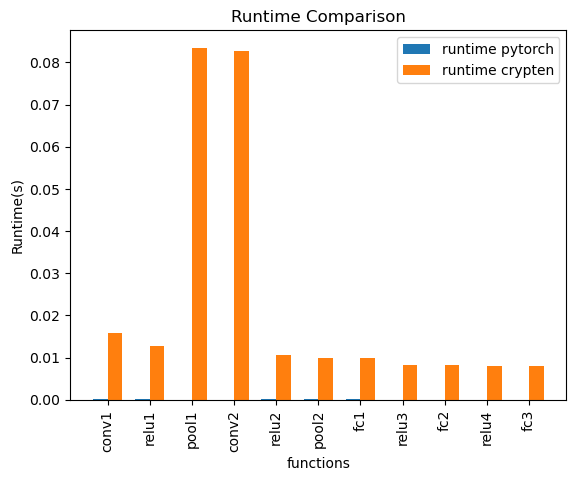

In [16]:
# 从CSV文件中读取数据
data = pd.read_csv('single_party/net_benchmarks_cuda.csv')
# print(data)
# 提取需要的列数据
functions = data['layer']
runtime_1 = data['runtime'] 
runtime_crypten_1 = data['runtime crypten']
# print(runtime)
# print(runtime_crypten)

# 绘制柱形图
bar_width = 0.35
index = range(len(functions))

plt.bar(index, runtime_1, bar_width, label='runtime pytorch')
plt.bar([i + bar_width for i in index], runtime_crypten_1, bar_width, label='runtime crypten')

# 设置横坐标刻度和标签
plt.xticks([i + bar_width/2 for i in index], functions, rotation='vertical')

# 添加图例
plt.legend()

# 添加标题和标签
plt.title('Runtime Comparison')
plt.xlabel('functions')
plt.ylabel('Runtime(s)')

# 保存
plt.savefig('img/Runtime Comparison in LeNet with gpu.png')

# 显示图形
plt.show()


In [17]:
# 从CSV文件中读取数据
data = pd.read_csv('multi_parties/2/net_benchmarks_cuda.csv')
runtime = []
runtime_crypten = []
runtime.append(runtime_1)
runtime_crypten.append(runtime_crypten_1)
for i in range(2,6):
    path = 'multi_parties/'+ str(i) +'/net_benchmarks_cuda.csv'
    data = pd.read_csv(path)
    runtime.append(data['runtime'])
    runtime_crypten.append(data['runtime crypten'])

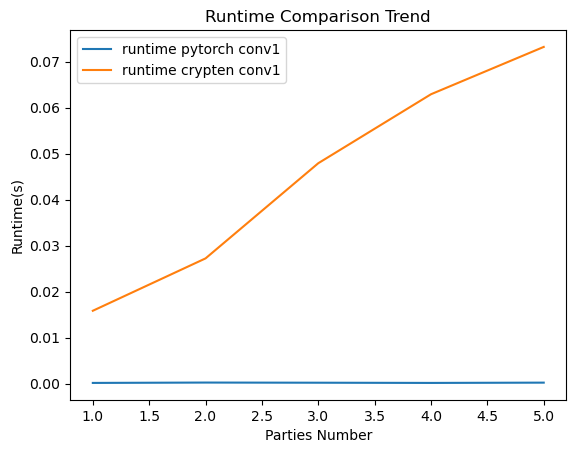

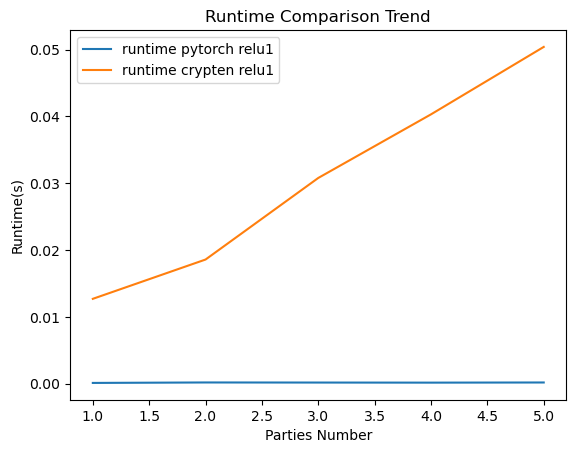

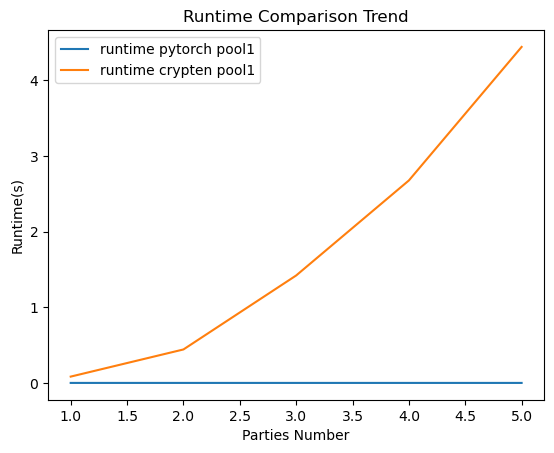

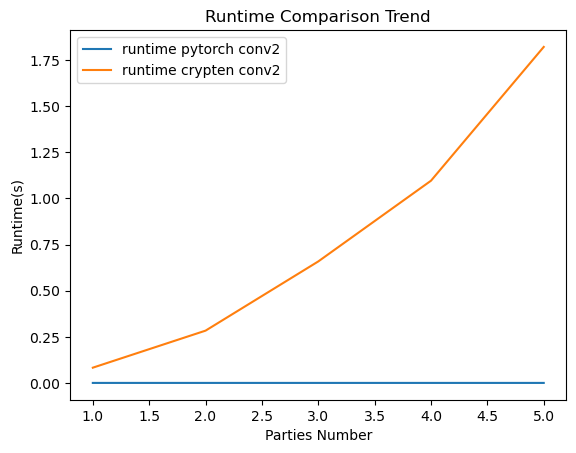

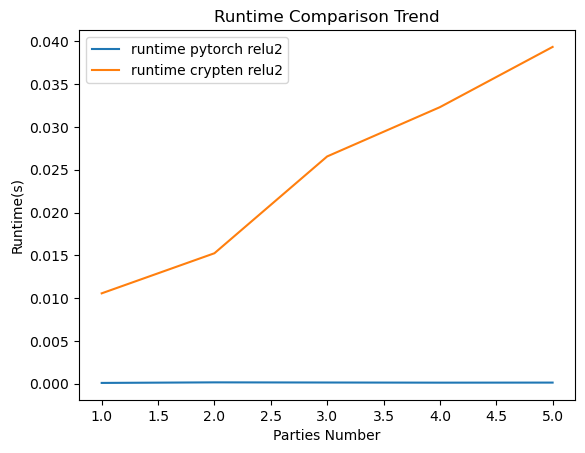

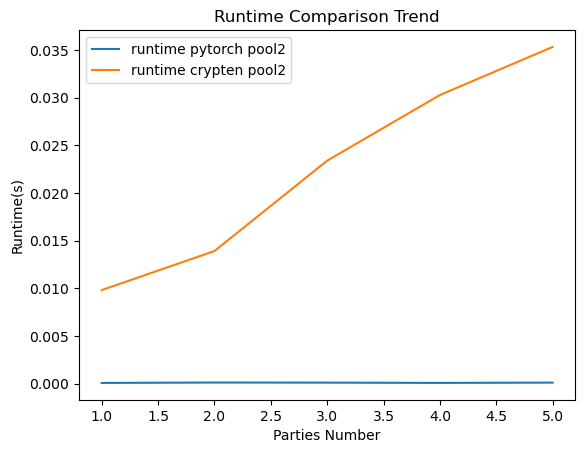

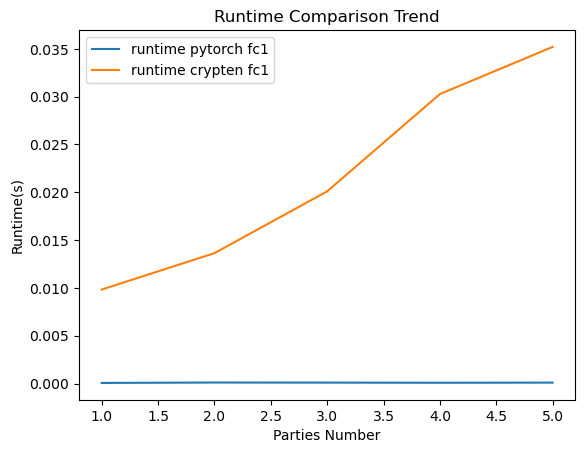

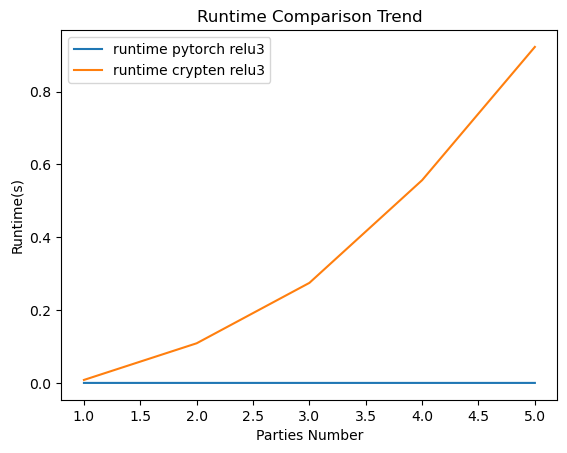

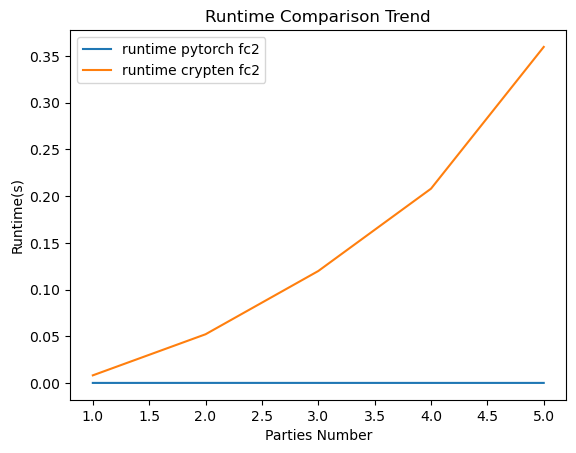

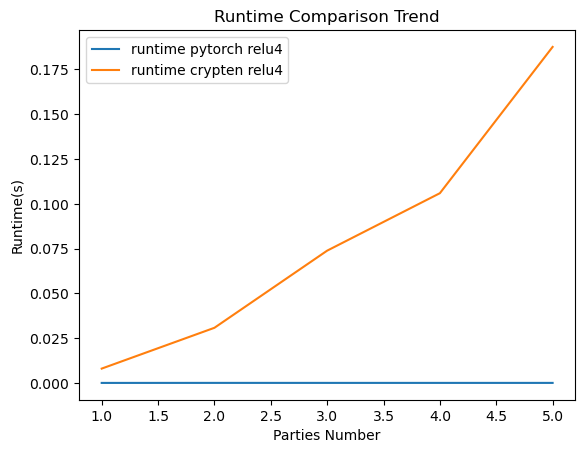

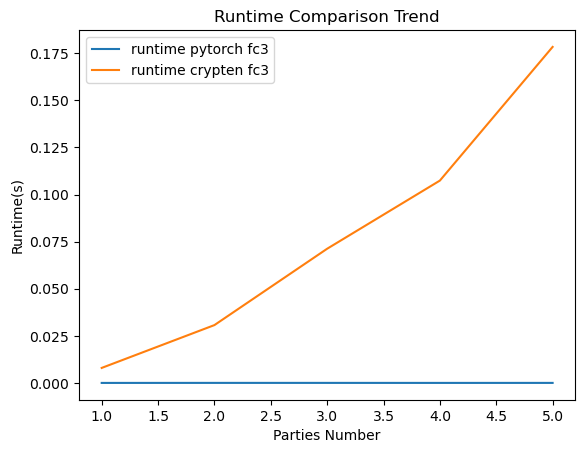

In [18]:
x = list(range(1,6))
for i in range(0,len(functions)): 
    y = []
    for ele in runtime:
        y.append(ele[i])
    plt.plot(x,y,label='runtime pytorch '+functions[i])
    
    y_crypten = []
    for ele in runtime_crypten:
        y_crypten.append(ele[i])
    plt.plot(x,y_crypten,label='runtime crypten '+functions[i])
    
    # 添加图例
    plt.legend()

    # 添加标题和标签
    plt.title('Runtime Comparison Trend')
    plt.xlabel('Parties Number')
    plt.ylabel('Runtime(s)')
    
    # 保存
    plt.savefig('img/Runtime Comparison Trend for ' + functions[i] + ' in LeNet with gpu.png')
    
    plt.show()


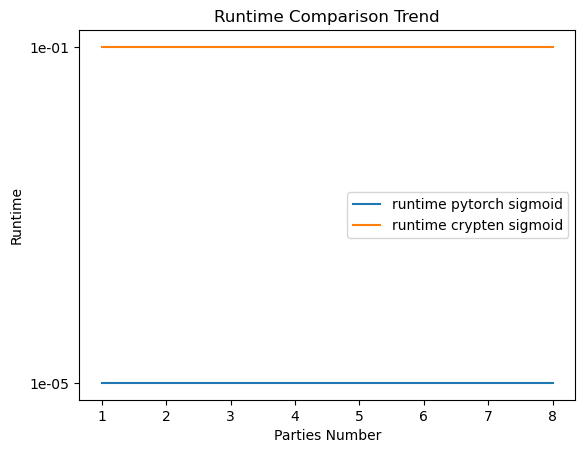

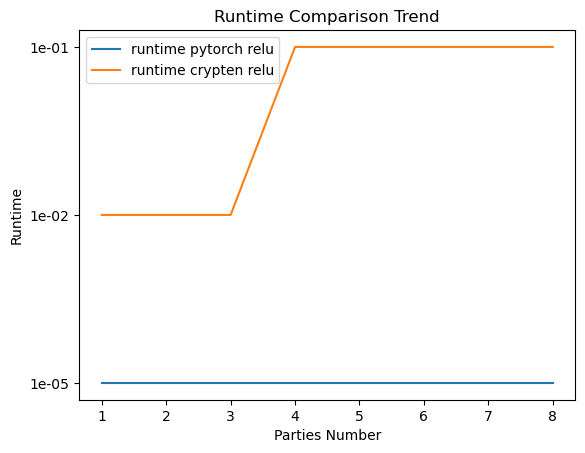

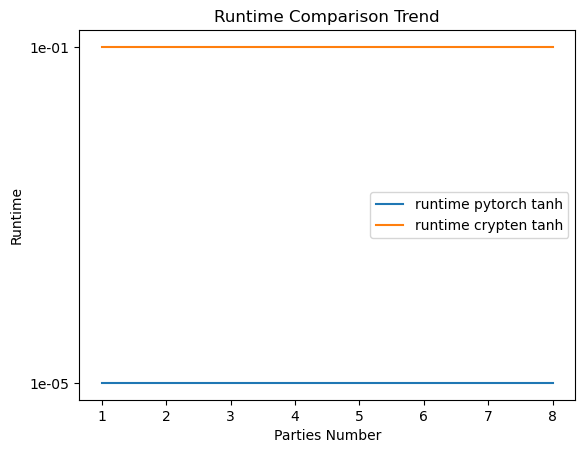

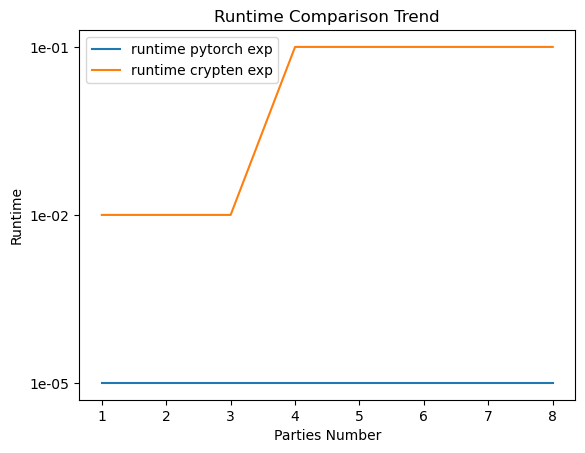

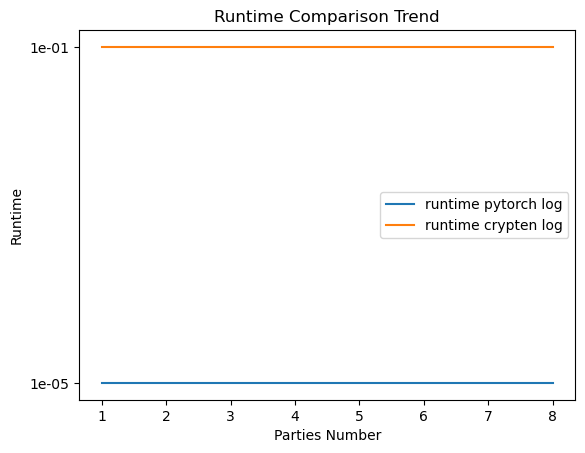

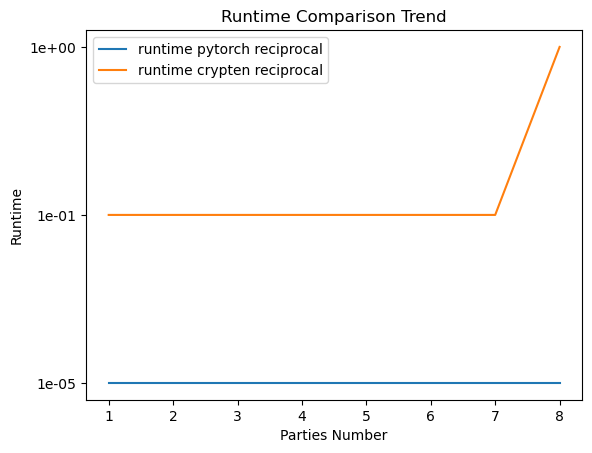

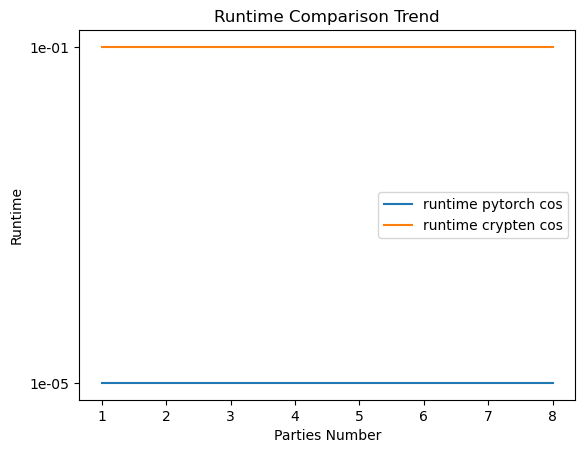

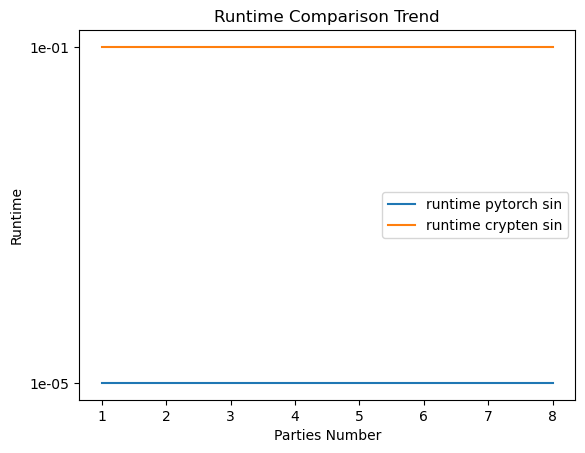

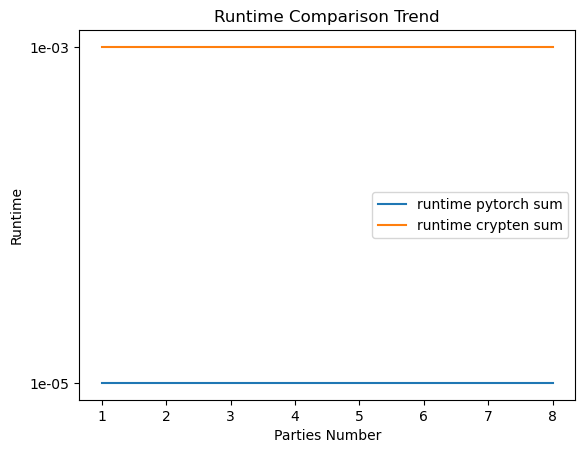

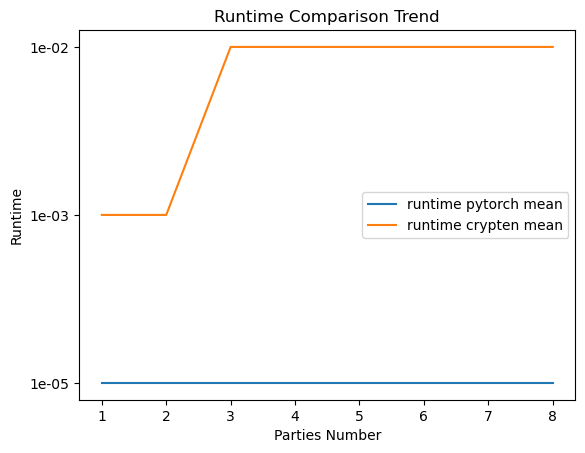

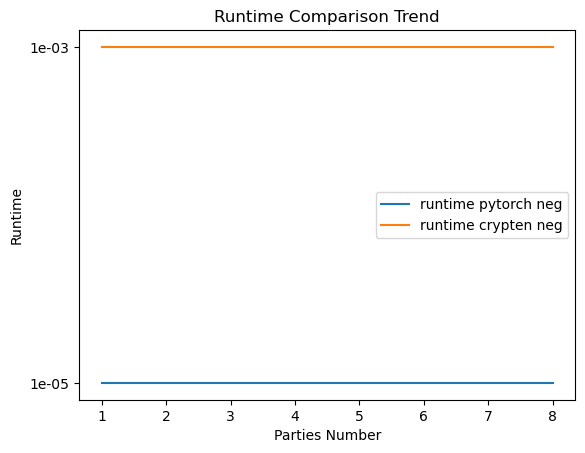

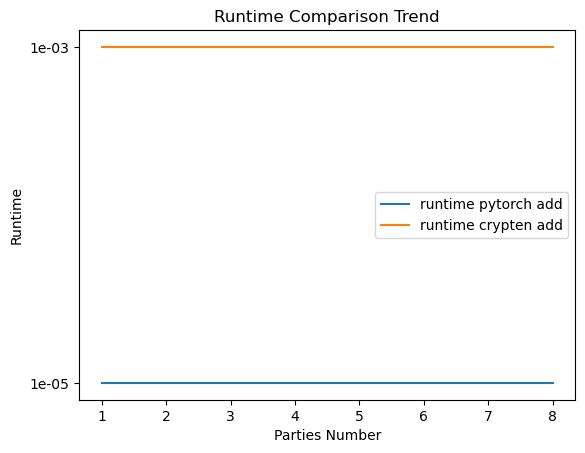

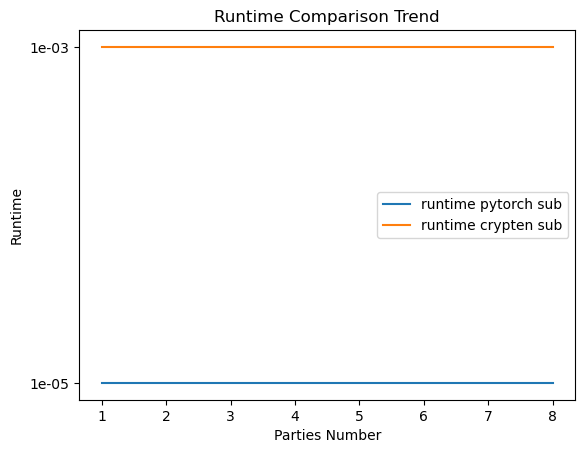

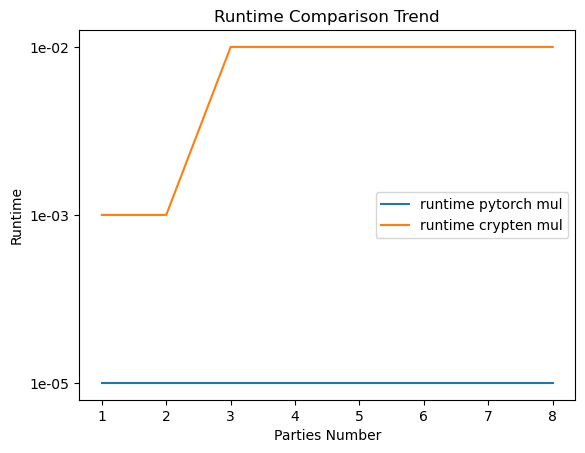

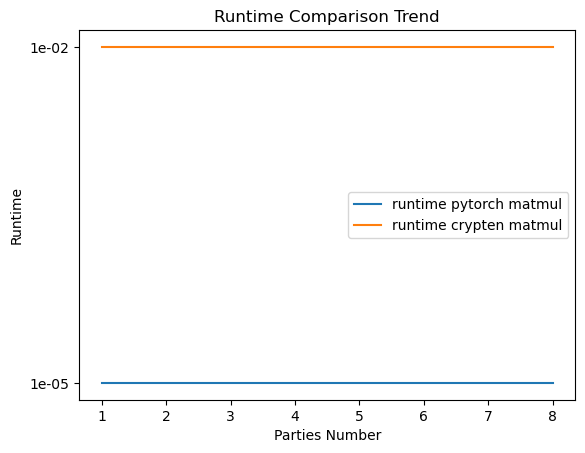

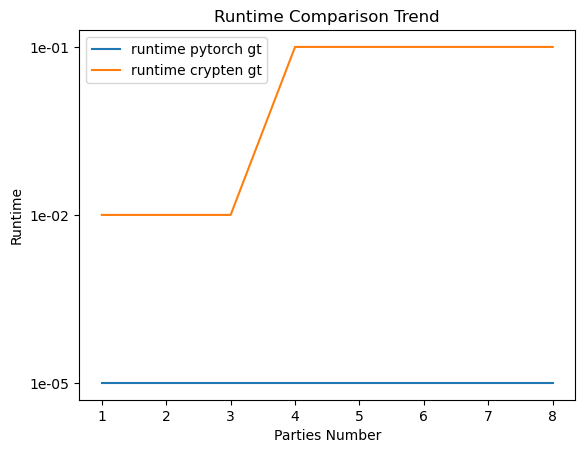

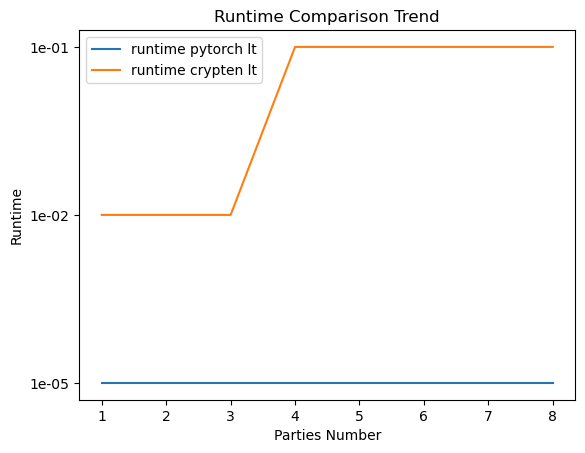

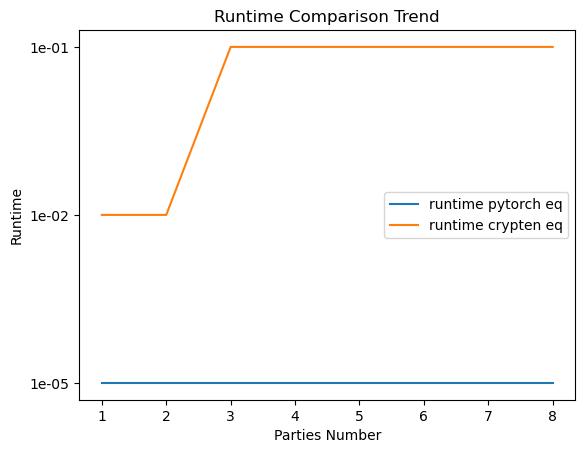

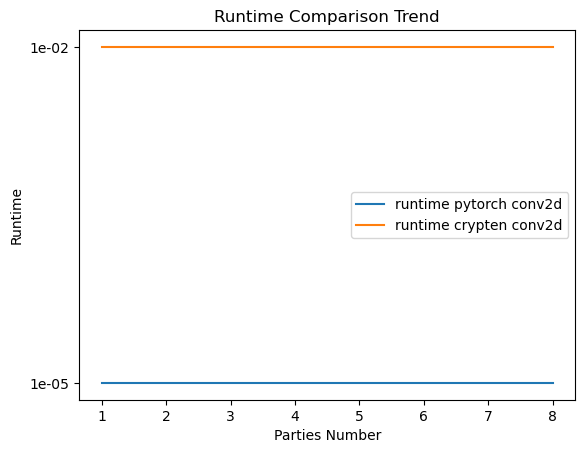

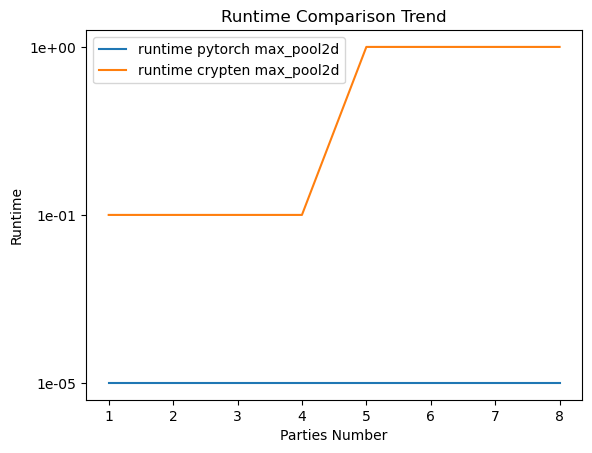

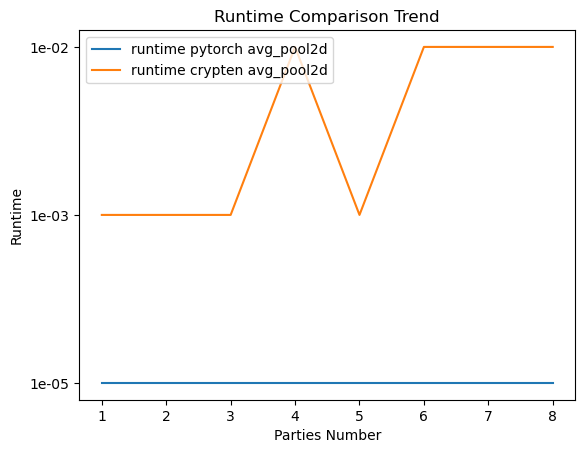

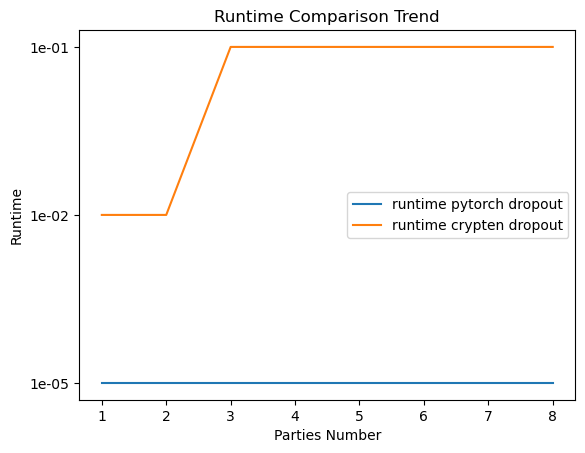

In [14]:
x = list(range(1,9))
for i in range(0,len(functions)): 
    y = []
    for ele in runtime:
        val = f'{ele[i]:e}'
        val = val.split('e')[1]
        y.append('1e'+val)
    plt.plot(x,y,label='runtime pytorch '+functions[i])
    
    y_crypten = []
    for ele in runtime_crypten:
        val = f'{ele[i]:e}'
        val = val.split('e')[1]
        y_crypten.append('1e'+val)
    plt.plot(x,y_crypten,label='runtime crypten '+functions[i])
    
    # 添加图例
    plt.legend()

    # 添加标题和标签
    plt.title('Runtime Comparison Trend')
    plt.xlabel('Parties Number')
    plt.ylabel('Runtime')
    
    # 保存
    plt.savefig('img_e/Runtime Comparison Trend for ' + functions[i] + ' in gpu.png')
    
    plt.show()


In [24]:
# 从CSV文件中读取数据
data = pd.read_csv('single_party/net_benchmarks_cuda.csv')
# print(data)
# 提取需要的列数据
functions = data['layer']
runtime_crypten_comm_1 = data['commtime crypten'] 
runtime_crypten_1 = data['runtime crypten']
print(runtime_crypten_comm_1)
print(runtime_crypten_1)

0     0.0
1     0.0
2     0.0
3     0.0
4     0.0
5     0.0
6     0.0
7     0.0
8     0.0
9     0.0
10    0.0
Name: commtime crypten, dtype: float64
0     0.015834
1     0.012706
2     0.083472
3     0.082657
4     0.010557
5     0.009808
6     0.009829
7     0.008230
8     0.008128
9     0.008014
10    0.007983
Name: runtime crypten, dtype: float64


In [25]:
# 从CSV文件中读取数据
data = pd.read_csv('multi_parties/2/net_benchmarks_cuda.csv')
runtime_crypten_comm = []
runtime_crypten = []
runtime_crypten_comm.append(runtime_crypten_comm_1)
runtime_crypten.append(runtime_crypten_1)
for i in range(2,6):
    path = 'multi_parties/'+ str(i) +'/net_benchmarks_cuda.csv'
    data = pd.read_csv(path)
    runtime_crypten_comm.append(data['commtime crypten'])
    runtime_crypten.append(data['runtime crypten'])

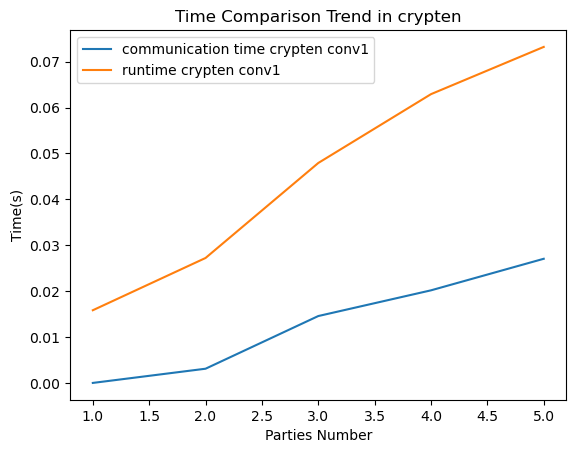

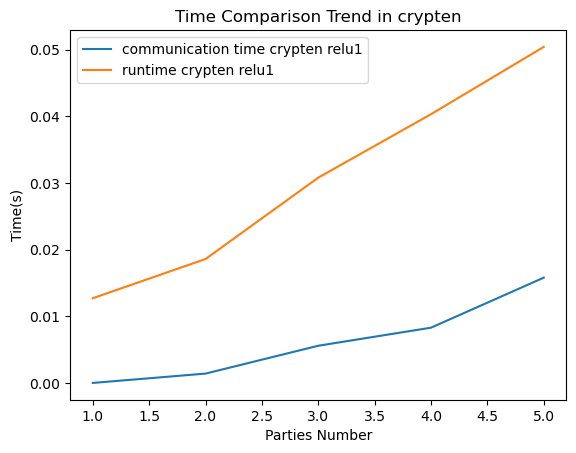

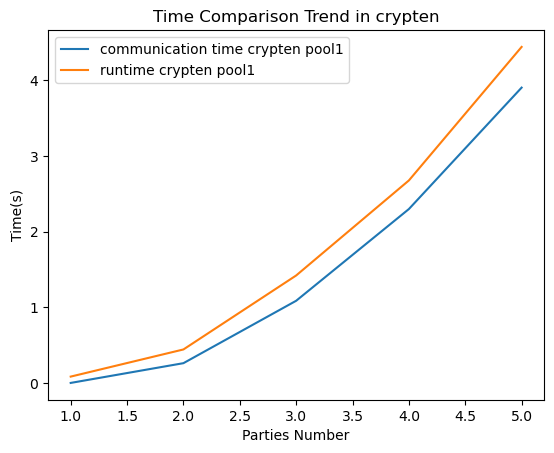

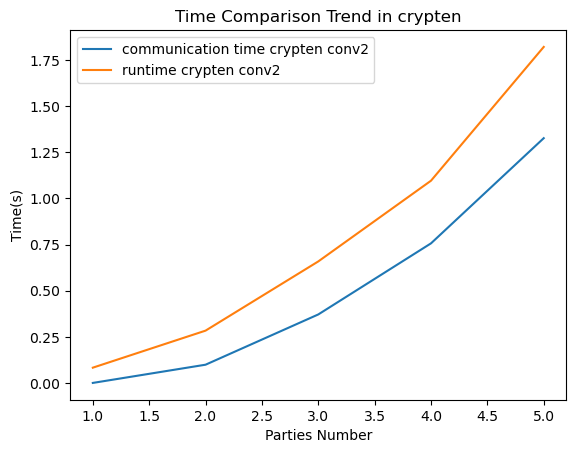

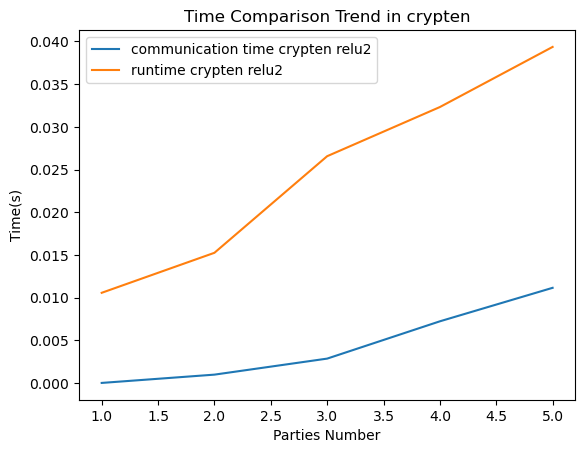

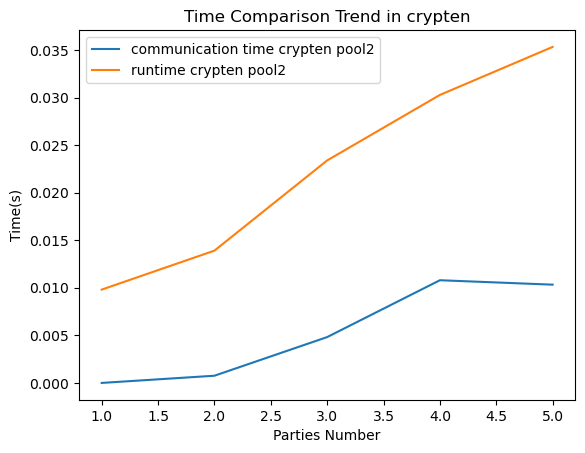

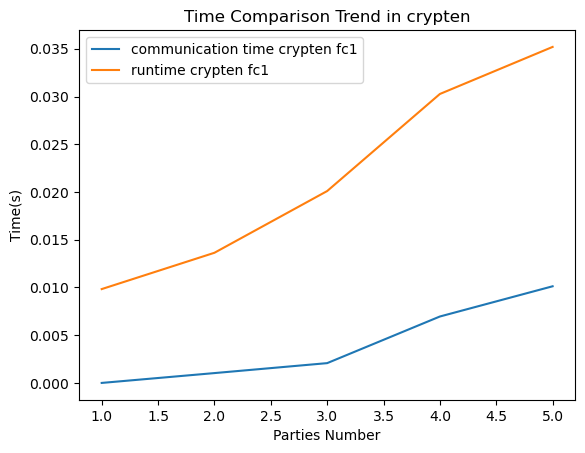

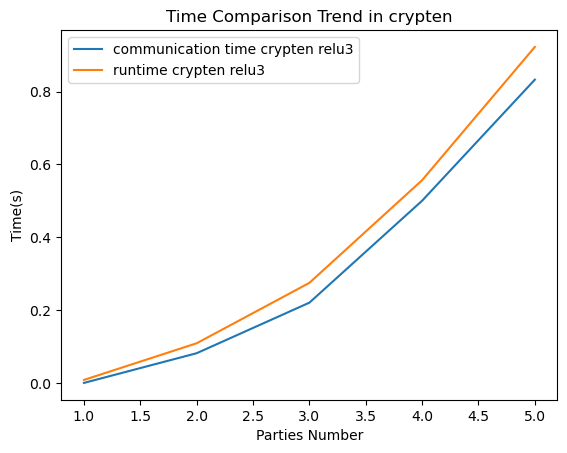

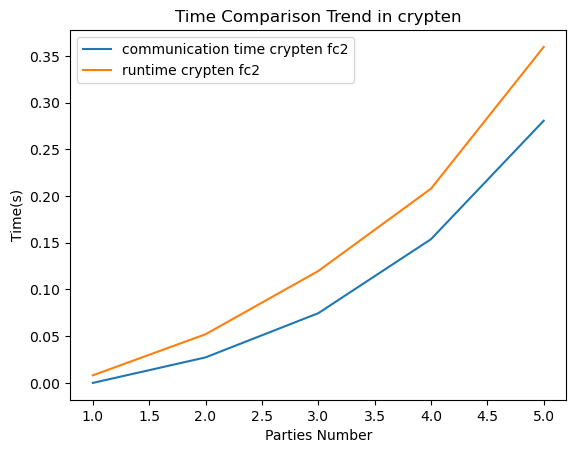

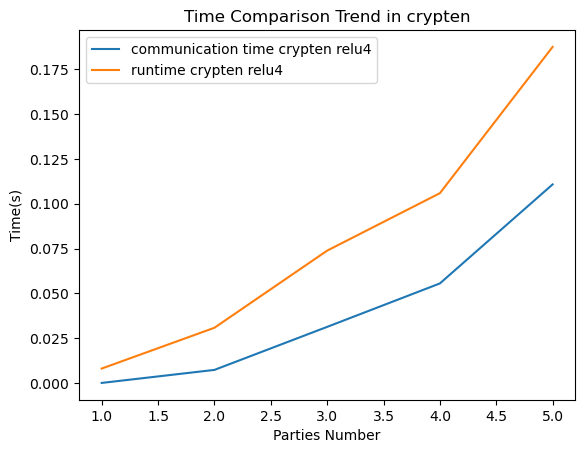

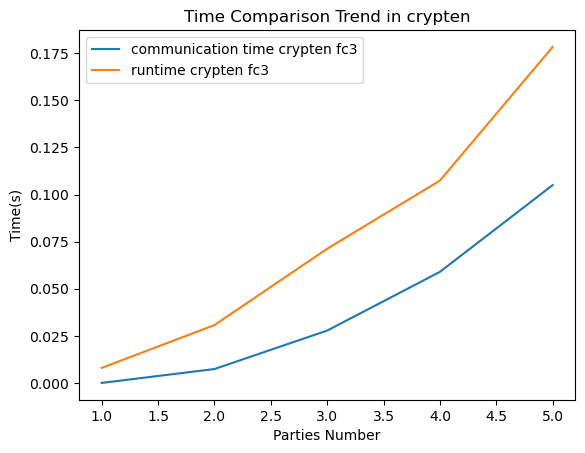

In [26]:
x = list(range(1,6))
for i in range(0,len(functions)): 
    y = []
    for ele in runtime_crypten_comm:
        y.append(ele[i])
    plt.plot(x,y,label='communication time crypten '+functions[i])
    
    y_crypten = []
    for ele in runtime_crypten:
        y_crypten.append(ele[i])
    plt.plot(x,y_crypten,label='runtime crypten '+functions[i])
    
    # 添加图例
    plt.legend()

    # 添加标题和标签
    plt.title('Time Comparison Trend in crypten')
    plt.xlabel('Parties Number')
    plt.ylabel('Time(s)')
    
    # 保存
    plt.savefig('img/Time Comparison Trend in crypten for ' + functions[i] + ' with gpu.png')
    
    plt.show()


In [2]:
import torch

In [3]:
matrix_tensor = torch.tensor([
    [3,4,9],
    [3,8,4],
    [9,3,4]
    ])

print(matrix_tensor)  

print(matrix_tensor.dim())  # 输出 2


tensor([[3, 4, 9],
        [3, 8, 4],
        [9, 3, 4]])
2


In [7]:
e_tensor = torch.exp(matrix_tensor)
s = torch.sum(e_tensor)
w = e_tensor / s
print(w)
res_tensor = w * matrix_tensor
print(res_tensor)
res = torch.sum(res_tensor)

tensor([[0.0010, 0.0028, 0.4174],
        [0.0010, 0.1536, 0.0028],
        [0.4174, 0.0010, 0.0028]])
tensor([[3.1042e-03, 1.1251e-02, 3.7570e+00],
        [3.1042e-03, 1.2286e+00, 1.1251e-02],
        [3.7570e+00, 3.1042e-03, 1.1251e-02]])
<class 'torch.Tensor'>
<class 'torch.Tensor'>
